# Geometric Brownian Motion (GBM) for Stock Simulation
1. Download historical prices from Yahoo Finance
2. Estimate **annualized expected return (μ)** and **volatility (σ)** from log returns
3. Generate **Brownian motion** paths
4. Apply **drift–diffusion dynamics** to simulate future price trajectories

$$dS_t = \mu S_t\,dt + \sigma S_t\,dW_t \;\;\Rightarrow\;\; S_t = S_0\exp\left[\left(\mu - \tfrac{1}{2}\sigma^2\right)t + \sigma W_t\right]$$

**Install:** `pip install yfinance numpy pandas matplotlib scipy`

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({"figure.figsize": (10, 5), "axes.grid": True, "grid.alpha": 0.3})

# ---- Settings ----
TICKER = "INFY.NS"
START, END = "2020-01-01", None     # END=None -> today
TRADING_DAYS = 252
HORIZON_DAYS = 252                  # forecast horizon
N_PATHS = 1000
SEED = 42

## 1. Historical data (Yahoo Finance)
If Yahoo Finance is unreachable, a synthetic price series is used so the notebook still runs.

Source: Yahoo Finance | 1683 observations | 2020-01-01 -> 2026-10-16


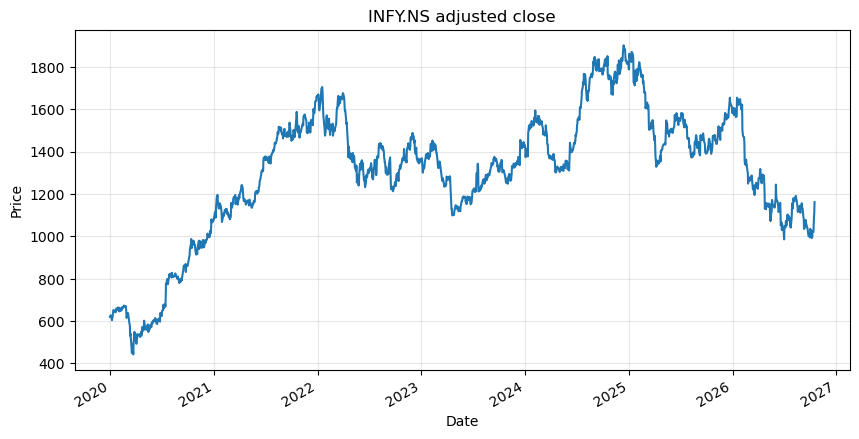

In [12]:
def load_prices(ticker, start, end=None):
    try:
        import yfinance as yf
        df = yf.download(ticker, start=start, end=end, auto_adjust=True, progress=False)
        s = df["Close"]
        if isinstance(s, pd.DataFrame):          # newer yfinance returns a column MultiIndex
            s = s.iloc[:, 0]
        s = s.dropna()
        if len(s) < 100:
            raise ValueError("not enough data")
        return s.rename(ticker), "Yahoo Finance"
    except Exception as e:
        print(f"[warning] Could not download data ({e}). Using synthetic data.")
        rng = np.random.default_rng(0)
        idx = pd.bdate_range("2020-01-01", periods=1500)
        r = rng.normal(0.0004, 0.018, len(idx))
        return pd.Series(150 * np.exp(np.cumsum(r)), index=idx, name=ticker), "Synthetic"

prices, source = load_prices(TICKER, START, END)
print(f"Source: {source} | {len(prices)} observations | {prices.index[0].date()} -> {prices.index[-1].date()}")
prices.plot(title=f"{TICKER} adjusted close"); plt.ylabel("Price"); plt.show()

## 2. Estimating μ and σ
With daily log returns $r_t = \ln(S_t/S_{t-1})$:

- $\hat\sigma = \text{std}(r_t)\sqrt{252}$
- mean log return annualized: $\bar r \cdot 252 = \mu - \tfrac12\sigma^2$, so the GBM drift is $\hat\mu = \bar r\cdot 252 + \tfrac12\hat\sigma^2$

The simple annualized arithmetic return is shown too for reference.

Annualized volatility (σ)        : 28.17%
Annualized mean log return       : 9.41%
GBM drift μ (= log mean + σ²/2)  : 13.38%
Annualized mean simple return    : 13.37%


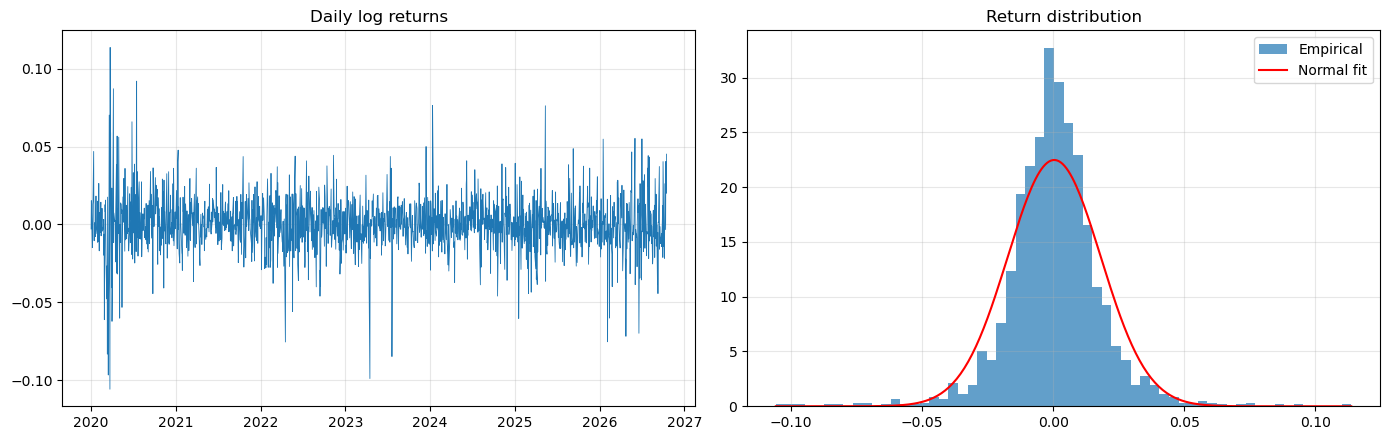

Skew: -0.131 | Excess kurtosis: 5.358  (GBM assumes 0 and 0)


In [13]:
log_ret = np.log(prices / prices.shift(1)).dropna()

sigma = log_ret.std() * np.sqrt(TRADING_DAYS)
mean_log_annual = log_ret.mean() * TRADING_DAYS
mu = mean_log_annual + 0.5 * sigma**2                      # GBM drift
simple_ret_annual = prices.pct_change().dropna().mean() * TRADING_DAYS

print(f"Annualized volatility (σ)        : {sigma:.2%}")
print(f"Annualized mean log return       : {mean_log_annual:.2%}")
print(f"GBM drift μ (= log mean + σ²/2)  : {mu:.2%}")
print(f"Annualized mean simple return    : {simple_ret_annual:.2%}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(log_ret, lw=0.6); ax[0].set_title("Daily log returns")
ax[1].hist(log_ret, bins=60, density=True, alpha=0.7, label="Empirical")
x = np.linspace(log_ret.min(), log_ret.max(), 300)
ax[1].plot(x, stats.norm.pdf(x, log_ret.mean(), log_ret.std()), "r", label="Normal fit")
ax[1].set_title("Return distribution"); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"Skew: {stats.skew(log_ret):.3f} | Excess kurtosis: {stats.kurtosis(log_ret):.3f}  (GBM assumes 0 and 0)")

## 3. Brownian motion paths
A standard Wiener process has $W_0=0$ and independent increments $W_{t+\Delta t}-W_t \sim N(0,\Delta t)$.

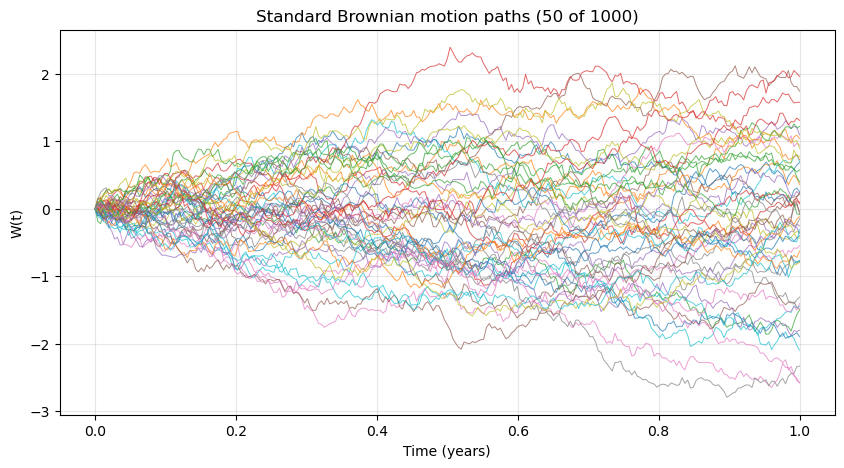

Var[W(T)] empirical: 0.9988 | theoretical: 1.0


In [14]:
def brownian_motion(n_paths, n_steps, T, seed=None):
    rng = np.random.default_rng(seed)
    dt = T / n_steps
    dW = rng.normal(0.0, np.sqrt(dt), size=(n_paths, n_steps))
    W = np.concatenate([np.zeros((n_paths, 1)), np.cumsum(dW, axis=1)], axis=1)
    return np.linspace(0, T, n_steps + 1), W

T = HORIZON_DAYS / TRADING_DAYS
t, W = brownian_motion(N_PATHS, HORIZON_DAYS, T, SEED)

plt.plot(t, W[:50].T, lw=0.7, alpha=0.7)
plt.title("Standard Brownian motion paths (50 of %d)" % N_PATHS); plt.xlabel("Time (years)"); plt.ylabel("W(t)")
plt.show()
print("Var[W(T)] empirical:", W[:, -1].var().round(4), "| theoretical:", T)

## 4. Drift–diffusion: simulating GBM

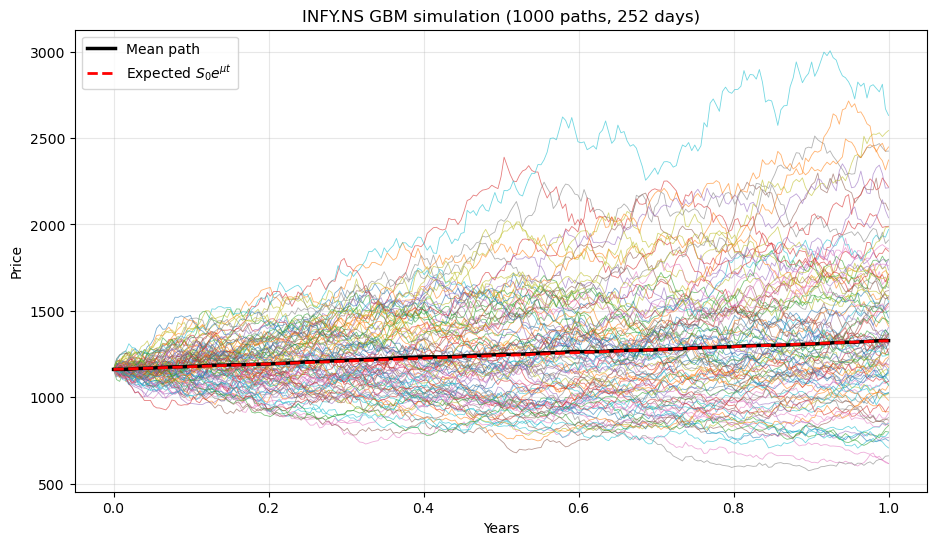

In [15]:
def simulate_gbm(S0, mu, sigma, T, n_steps, n_paths, seed=None):
    t, W = brownian_motion(n_paths, n_steps, T, seed)
    S = S0 * np.exp((mu - 0.5 * sigma**2) * t + sigma * W)      # exact solution
    return t, S

S0 = float(prices.iloc[-1])
t, S = simulate_gbm(S0, mu, sigma, T, HORIZON_DAYS, N_PATHS, SEED)

fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(t, S[:100].T, lw=0.6, alpha=0.6)
ax.plot(t, S.mean(axis=0), "k", lw=2.5, label="Mean path")
ax.plot(t, S0 * np.exp(mu * t), "r--", lw=2, label=r"Expected $S_0e^{\mu t}$")
ax.set(title=f"{TICKER} GBM simulation ({N_PATHS} paths, {HORIZON_DAYS} days)", xlabel="Years", ylabel="Price")
ax.legend(); plt.show()

### Past + future

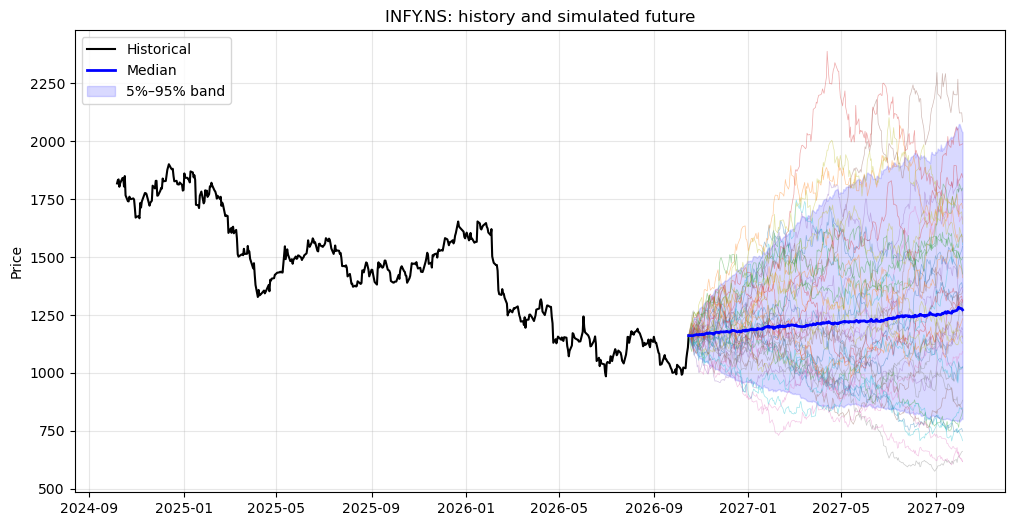

In [16]:
future_idx = pd.bdate_range(prices.index[-1], periods=HORIZON_DAYS + 1)
sim_df = pd.DataFrame(S.T, index=future_idx)
lo, med, hi = sim_df.quantile(0.05, axis=1), sim_df.median(axis=1), sim_df.quantile(0.95, axis=1)

fig, ax = plt.subplots(figsize=(12, 6))
hist = prices.iloc[-504:]
ax.plot(hist.index, hist.values, color="black", label="Historical")
ax.plot(future_idx, S[:40].T, lw=0.5, alpha=0.4)
ax.plot(med, "b", lw=2, label="Median"); ax.fill_between(future_idx, lo, hi, color="blue", alpha=0.15, label="5%–95% band")
ax.set(title=f"{TICKER}: history and simulated future", ylabel="Price"); ax.legend(); plt.show()

## 5. Terminal price distribution & risk metrics

Starting price                1161.2000
Mean terminal price           1327.7812
Theoretical mean S0·e^(μT)    1327.3932
Median terminal price         1272.3562
5th percentile                 800.7172
95th percentile               2039.7438
P(S_T > S_0)                     0.6220
VaR 95% (return)                -0.3104
Expected shortfall 95%          -0.3766


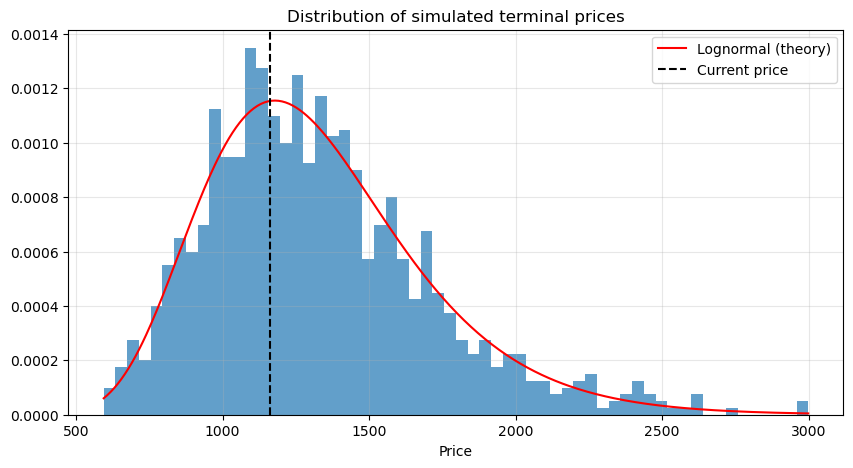

In [17]:
ST = S[:, -1]
ret = ST / S0 - 1
stats_tbl = pd.Series({
    "Starting price": S0,
    "Mean terminal price": ST.mean(),
    "Theoretical mean S0·e^(μT)": S0 * np.exp(mu * T),
    "Median terminal price": np.median(ST),
    "5th percentile": np.percentile(ST, 5),
    "95th percentile": np.percentile(ST, 95),
    "P(S_T > S_0)": (ST > S0).mean(),
    "VaR 95% (return)": np.percentile(ret, 5),
    "Expected shortfall 95%": ret[ret <= np.percentile(ret, 5)].mean(),
})
print(stats_tbl.round(4).to_string())

plt.hist(ST, bins=60, density=True, alpha=0.7)
# Terminal price is lognormal: ln(S_T) ~ N(ln S0 + (mu - σ²/2)T, σ²T)
xs = np.linspace(ST.min(), ST.max(), 400)
plt.plot(xs, stats.lognorm.pdf(xs, s=sigma * np.sqrt(T), scale=S0 * np.exp((mu - 0.5 * sigma**2) * T)), "r", label="Lognormal (theory)")
plt.axvline(S0, color="k", ls="--", label="Current price"); plt.legend()
plt.title("Distribution of simulated terminal prices"); plt.xlabel("Price"); plt.show()

## 6. Model check: backtest on held-out data
Estimate μ, σ from the first ~80% of history, simulate the remaining period, and check whether actual prices fall in the simulated 90% band.

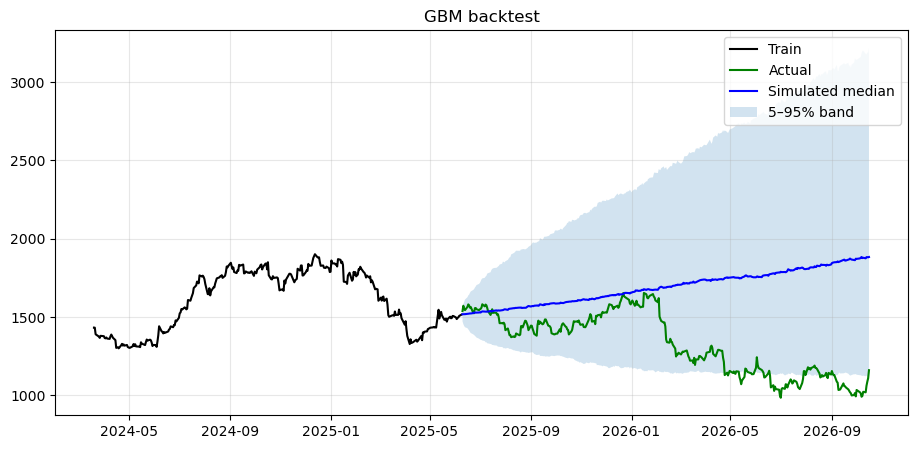

Share of actual prices inside the 90% band: 76.3%


In [18]:
split = int(len(prices) * 0.8)
train, test = prices.iloc[:split], prices.iloc[split:]
lr = np.log(train / train.shift(1)).dropna()
sig_tr = lr.std() * np.sqrt(TRADING_DAYS); mu_tr = lr.mean() * TRADING_DAYS + 0.5 * sig_tr**2
n = len(test); T_tr = n / TRADING_DAYS
t_b, S_b = simulate_gbm(float(train.iloc[-1]), mu_tr, sig_tr, T_tr, n, 2000, SEED)
idx = test.index
bt = pd.DataFrame(S_b[:, 1:].T, index=idx)
lo, hi = bt.quantile(0.05, axis=1), bt.quantile(0.95, axis=1)

plt.figure(figsize=(11, 5))
plt.plot(train.iloc[-300:], "k", label="Train")
plt.plot(test, "g", label="Actual")
plt.plot(bt.median(axis=1), "b", label="Simulated median")
plt.fill_between(idx, lo, hi, alpha=0.2, label="5–95% band"); plt.legend(); plt.title("GBM backtest"); plt.show()
print(f"Share of actual prices inside the 90% band: {((test >= lo) & (test <= hi)).mean():.1%}")

## Notes & limitations
- GBM assumes constant μ and σ and normally distributed log returns; real returns show fat tails, volatility clustering, and jumps (see the kurtosis above).
- Estimates of μ are very noisy — the drift is hard to estimate from a few years of data, so long-horizon forecasts are dominated by uncertainty.
- Extensions: Heston (stochastic vol), Merton jump-diffusion, GARCH volatility, multi-asset correlated GBM via Cholesky decomposition.